# The Machine Learning Workflow: Exploratory Data Analysis (Milestone 1)

**Project:** Home Credit Default Risk  
**Team:** _add names here_  
**Date:** _add date_

This notebook covers **Milestone 1 (EDA)**. The goal is to understand which information in the data might help to predict default, and which problems need fixing before modelling. No models are trained here.

### Definition of done
- I know what the key numeric and categorical columns look like and which values are unusual or wrong.
- I know which columns show a clear relationship with `TARGET`.
- I know how missing values relate to `TARGET`.
- I have looked at the side tables and have a plan for aggregating them.
- Findings and feature ideas are written down in the summary.

## Business goal (recap)

The stakeholder is a **credit risk manager at Home Credit**. They need to decide which loan applications to approve, using only information known at the time of the application. The task is **binary classification** of `TARGET` (1 = repayment difficulties), with ROC-AUC as the main metric because only about 8% of applicants default.


## 1. Setup

**Hints**
- Import `pandas`, `numpy`, `matplotlib` and `seaborn`.
- Set `DATA_DIR` to your data folder, and set a consistent plot style.
- Set pandas display options so that wide tables are readable.

In [1]:
import pandas as pd
import numpy as np  
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
from pathlib import Path

DATA_DIR = Path("data/home-credit-default-risk")

pd.set_option("display.max_columns", 130)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

## 2. Load the data

Load `application_train` first. This is the main table for the EDA. Load the side tables later, in section 10.

**Hints**
- Keep a clean copy of the original and work on a copy with `.copy()`, so you can always go back.
- Check the shape after loading. It should be (307511, 122).

In [3]:
app_train_raw = pd.read_csv(DATA_DIR / "application_train.csv")
app_train = app_train_raw.copy()

print(app_train.shape)
app_train.head()

(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

## 3. The target variable (recap)

**Hint:** In Milestone 0 we found that about 8% of applicants have `TARGET` = 1. Recompute the default rate here and keep the number in a variable, for example `base_rate`. We will compare other groups against it.

In [4]:
base_rate = app_train["TARGET"].mean()
print(f"Default rate: {base_rate:.2%}")

Default rate: 8.07%


## 4. Numeric columns: distributions

Look at the shape of the most important numeric columns before relating them to `TARGET`.

**Suggested columns:** `AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`, `DAYS_BIRTH`, `DAYS_EMPLOYED`, `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`.

**Questions to answer**
1. Which columns are strongly skewed? (Income and credit amounts usually are.)
2. Are there extreme outliers?
3. Would a log scale make a distribution easier to read?

**Hints**
- Use `describe()` for numbers and histograms for shapes.
- Use `plt.subplots` with a loop to draw several histograms in one figure.
- `DAYS_*` columns are negative, because they count days back from the application date. Convert `DAYS_BIRTH` to age in years for plotting.

In [5]:
app_train["AGE_YEARS"] = -app_train["DAYS_BIRTH"] / 365

num_cols = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
            "AGE_YEARS", "DAYS_EMPLOYED", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

app_train[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.92,237123.15,25650.00,112500.00,147150.00,202500.00,1.170000e+08
AMT_CREDIT,307511.0,599026.00,402490.78,45000.00,270000.00,513531.00,808650.00,4.050000e+06
AMT_ANNUITY,307499.0,27108.57,14493.74,1615.50,16524.00,24903.00,34596.00,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.21,369446.46,40500.00,238500.00,450000.00,679500.00,4.050000e+06
AGE_YEARS,307511.0,43.94,11.96,20.52,34.01,43.15,53.92,6.912000e+01
DAYS_EMPLOYED,307511.0,63815.05,141275.77,-17912.00,-2760.00,-1213.00,-289.00,3.652430e+05
EXT_SOURCE_1,134133.0,0.50,0.21,0.01,0.33,0.51,0.68,9.600000e-01
EXT_SOURCE_2,306851.0,0.51,0.19,0.00,0.39,0.57,0.66,8.500000e-01
EXT_SOURCE_3,246546.0,0.51,0.19,0.00,0.37,0.54,0.67,9.000000e-01


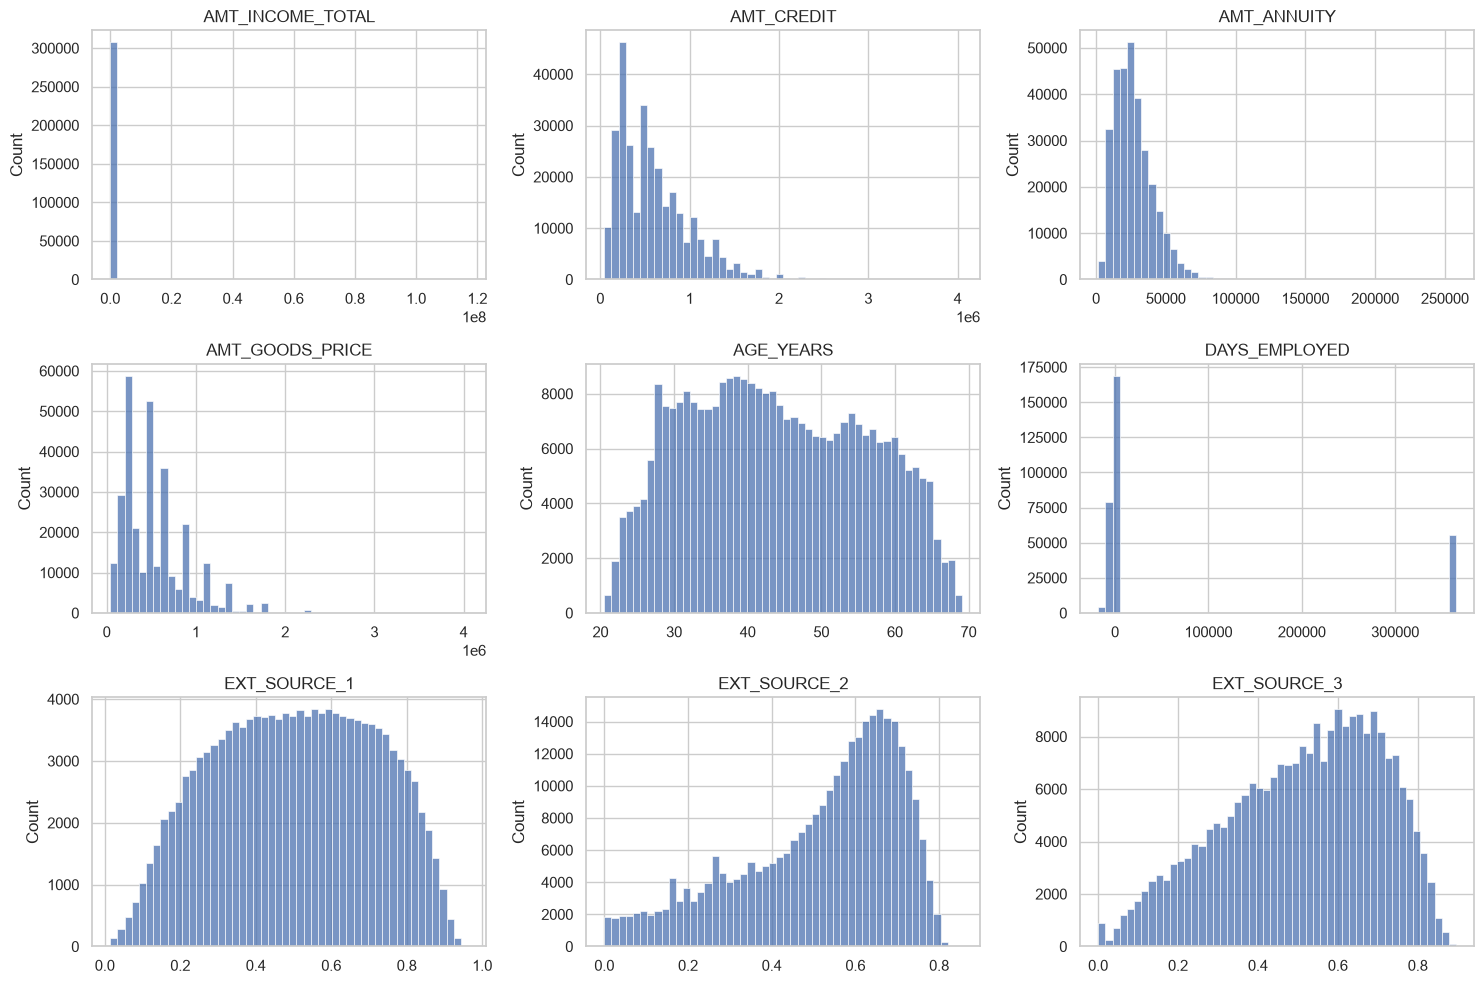

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(app_train[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

- The money columns (`AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`) are strongly right-skewed. A log scale would make them easier to read.
- `AMT_INCOME_TOTAL` has an extreme outlier (over 100 million), which squeezes the histogram into one bar.
- `AGE_YEARS` is spread from 20 to 70. The `EXT_SOURCE` columns lie between 0 and 1.
- `DAYS_EMPLOYED` has a separate group at about 365,000 days (about 1,000 years), which is impossible, so it is a placeholder value.

## 5. Anomalies and wrong values

Real data contains placeholders and impossible values. Find them now, because they can mislead a model.

**Things to check**
- `DAYS_EMPLOYED`: look at the maximum value. Is it realistic? How many rows have it, and what is their default rate compared to the rest?
- Categorical columns with a placeholder category such as `XNA` (for example `CODE_GENDER`, `ORGANIZATION_TYPE`).
- Very large values in `AMT_INCOME_TOTAL`.
- Negative or zero values where they should not occur.

**Hints**
- Use `value_counts()` on suspicious values and `.max()`/`.min()` on numeric columns.
- To compare groups, use `groupby(...)["TARGET"].mean()`.
- Write down every anomaly and how you plan to treat it. Do not fix anything yet.

In [7]:
print(app_train["DAYS_EMPLOYED"].describe())
# XNA means “not available”.

same = (app_train["ORGANIZATION_TYPE"] == "XNA") == (app_train["DAYS_EMPLOYED"] == 365243)
print("same rows flagged by both:", same.mean().round(4))

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64
same rows flagged by both: 1.0


In [8]:
anom = app_train["DAYS_EMPLOYED"] == 365243
print("group size:", anom.sum())
print("anomaly group default rate:", round(app_train.loc[anom, "TARGET"].mean(), 4))
print("other rows default rate:   ", round(app_train.loc[~anom, "TARGET"].mean(), 4))

group size: 55374
anomaly group default rate: 0.054
other rows default rate:    0.0866


**Anomalies and wrong values**

- `DAYS_EMPLOYED` has the placeholder value 365243 (about 1,000 years). All other values are negative, with a median of about 3.3 years. The placeholder pushes the mean to a positive number and distorts the distribution.
- 55,374 applicants (18%) have this placeholder. Their default rate is 5.40%, against 8.66% for everyone else, so the group carries information and must not be dropped.
- The same applicants have `ORGANIZATION_TYPE` = `XNA` (100% overlap), so it is one group with no employment information, probably pensioners and unemployed people.
- Treatment: replace 365243 with NaN and keep a flag column `DAYS_EMPLOYED_ANOM` (1 = placeholder). After the fix, the maximum of `DAYS_EMPLOYED` is 0 and the flag is 1 for 18.01% of applicants.
- `AMT_INCOME_TOTAL` has an extreme outlier of over 100 million. Plan: cap the value or use a log transform before modelling.
- `CODE_GENDER` has a few `XNA` rows. Plan: treat them as missing or drop them, since there are very few.

In [9]:
app_train["DAYS_EMPLOYED_ANOM"] = (app_train["DAYS_EMPLOYED"] == 365243).astype(int)
app_train["DAYS_EMPLOYED"] = app_train["DAYS_EMPLOYED"].replace(365243, np.nan)

print(app_train["DAYS_EMPLOYED"].max())
print(app_train["DAYS_EMPLOYED_ANOM"].mean().round(4))

0.0
0.1801


In [10]:
print(app_train["AMT_INCOME_TOTAL"].max())
print((app_train["CODE_GENDER"] == "XNA").sum())

117000000.0
4


- `AMT_INCOME_TOTAL` has an extreme outlier of 117 million. Plan: cap the value or use a log transform before modelling.
- `CODE_GENDER` has 4 `XNA` rows. Plan: treat them as missing or drop them, since there are so few.

## 6. Categorical columns versus `TARGET`

For each categorical column, compare the **default rate per category** with the overall default rate. A category with a clearly higher or lower rate carries information.

**Suggested columns:** `NAME_CONTRACT_TYPE`, `CODE_GENDER`, `NAME_INCOME_TYPE`, `NAME_EDUCATION_TYPE`, `NAME_FAMILY_STATUS`, `NAME_HOUSING_TYPE`, `OCCUPATION_TYPE`, `ORGANIZATION_TYPE`.

**Questions to answer**
1. Which categories have the highest and lowest default rates?
2. Are the differences large, or are the groups too small to trust? (Check the group sizes too.)

**Hints**
- Compute `groupby(col)["TARGET"].agg(["mean", "count"])`.
- Draw a bar chart of the mean default rate per category and add a horizontal line for the overall rate.
- Write a small function that takes a column name and draws the chart, so you can reuse it.

In [11]:
def plot_default_rate(df, col, min_count=500):
    stats = (df.groupby(col)["TARGET"].agg(["mean", "count"])
               .query("count >= @min_count")
               .sort_values("mean", ascending=False))
    stats["mean"].plot(kind="bar", figsize=(10, 4))
    plt.axhline(df["TARGET"].mean(), color="red", linestyle="--", label="overall rate")
    plt.title(f"Default rate by {col}")
    plt.ylabel("default rate")
    plt.legend()
    plt.show()
    return stats.round(4)

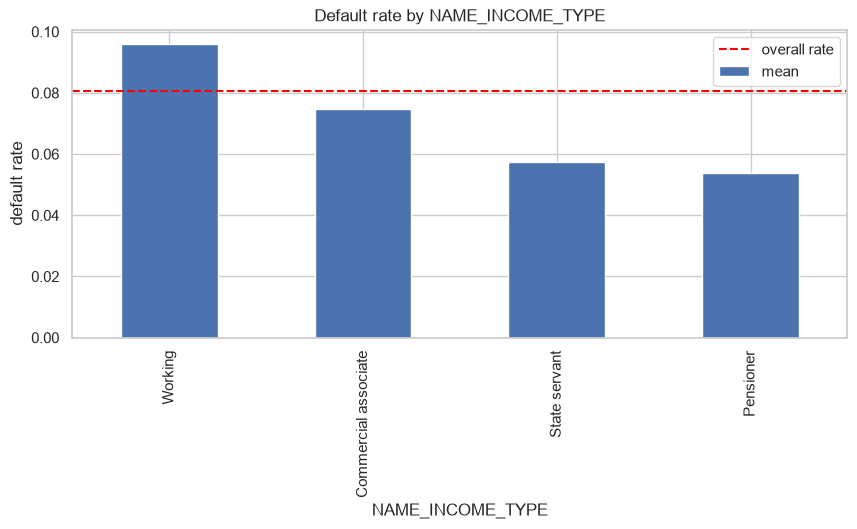

,mean,count
NAME_INCOME_TYPE,,
Working,0.0959,158774
Commercial associate,0.0748,71617
State servant,0.0575,21703
Pensioner,0.0539,55362


In [12]:
plot_default_rate(app_train, "NAME_INCOME_TYPE")

- `NAME_INCOME_TYPE`: Working applicants have the highest default rate (about 9.6%, above the overall 8%). State servants (about 5.7%) and pensioners (about 5.3%) have the lowest. The very small groups (for example students) are hidden because they are too small to trust.

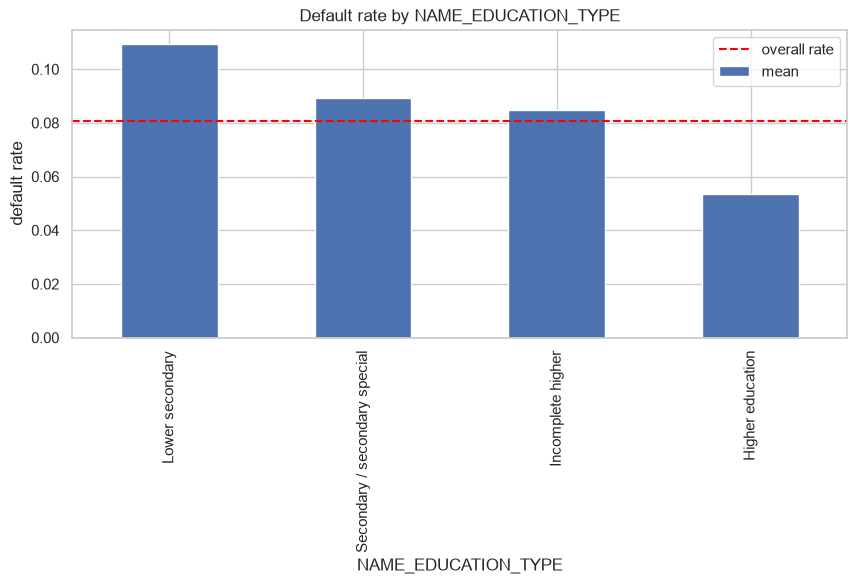

,mean,count
NAME_EDUCATION_TYPE,,
Lower secondary,0.1093,3816
Secondary / secondary special,0.0894,218391
Incomplete higher,0.0848,10277
Higher education,0.0536,74863


In [13]:
plot_default_rate(app_train, "NAME_EDUCATION_TYPE")

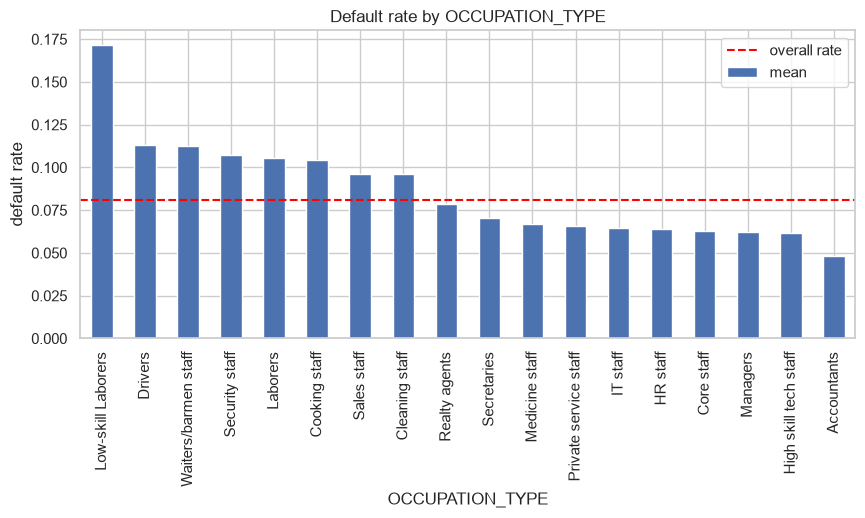

,mean,count
OCCUPATION_TYPE,,
Low-skill Laborers,0.1715,2093
Drivers,0.1133,18603
Waiters/barmen staff,0.1128,1348
Security staff,0.1074,6721
Laborers,0.1058,55186
Cooking staff,0.1044,5946
Sales staff,0.0963,32102
Cleaning staff,0.0961,4653
Realty agents,0.0786,751


In [14]:
plot_default_rate(app_train, "OCCUPATION_TYPE")

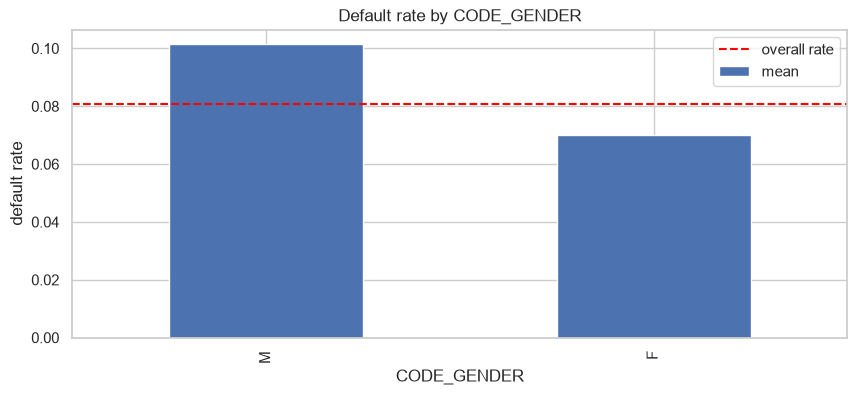

,mean,count
CODE_GENDER,,
M,0.1014,105059
F,0.0700,202448


In [15]:
plot_default_rate(app_train, "CODE_GENDER")

- `NAME_INCOME_TYPE`: Working applicants have the highest default rate (about 9.6%). State servants (about 5.7%) and pensioners (about 5.3%) have the lowest. Very small groups are hidden because they are too small to trust.
- `CODE_GENDER`: men default more often (10.1%) than women (7.0%). Both groups are large, so the difference is reliable. Using gender in credit decisions can be legally and ethically problematic, so I will check the model without it.
- `OCCUPATION_TYPE`: accountants (4.8%), high-skill tech staff (6.2%) and managers (6.2%) have the lowest default rates. _Add the highest ones from your table._
- `NAME_EDUCATION_TYPE`: _add what you find._
- Overall, the differences between the large groups are meaningful, while the very small groups are too small to trust.

## 7. Numeric columns versus `TARGET`

Compare the distribution of a numeric column for defaulters and non-defaulters. If the two distributions differ, the column helps to separate the groups.

**Suggested columns:** `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`, age in years, `AMT_CREDIT`, `DAYS_EMPLOYED` (without the anomaly).

**Questions to answer**
1. Which columns separate the two groups best?
2. Is a higher or lower value linked to a higher risk?

**Hints**
- Use a KDE plot or histogram with `hue="TARGET"` and `common_norm=False`, so the 8% minority is not drowned out.
- Another good view is to bin a numeric column (for example age in 10-year groups) and plot the default rate per bin.

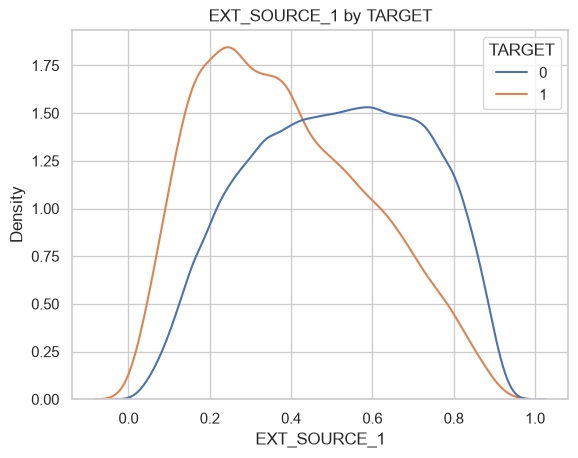

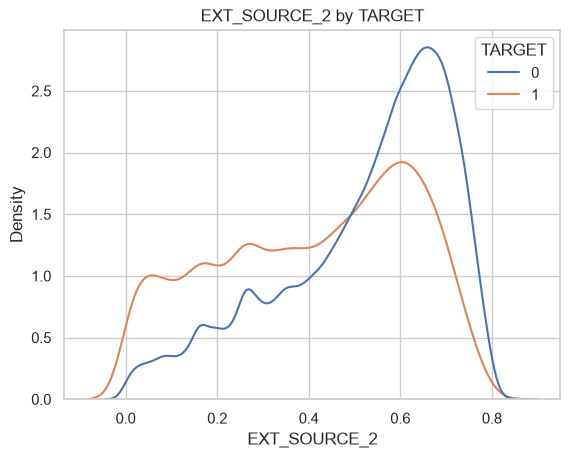

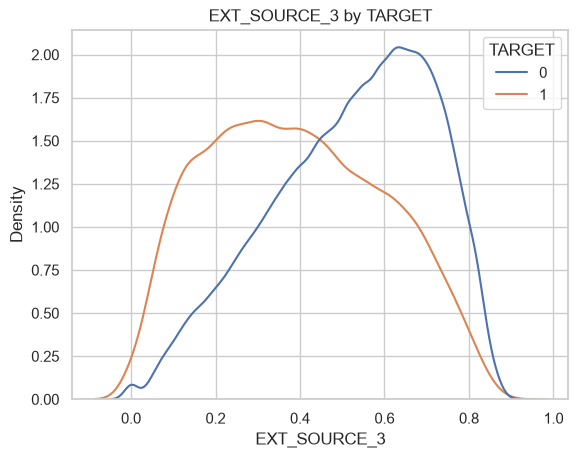

In [16]:
for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    sns.kdeplot(data=app_train, x=col, hue="TARGET", common_norm=False)
    plt.title(f"{col} by TARGET")
    plt.show()

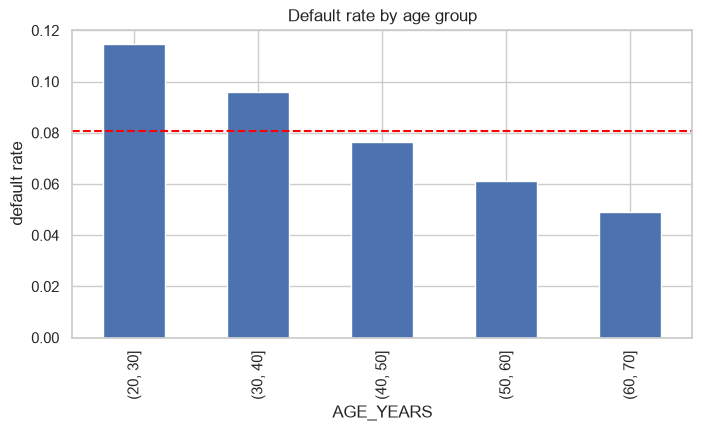

In [17]:
age_bins = pd.cut(app_train["AGE_YEARS"], bins=range(20, 80, 10))
age_rate = app_train.groupby(age_bins, observed=True)["TARGET"].mean()

age_rate.plot(kind="bar", figsize=(8, 4))
plt.axhline(app_train["TARGET"].mean(), color="red", linestyle="--")
plt.title("Default rate by age group")
plt.ylabel("default rate")
plt.show()

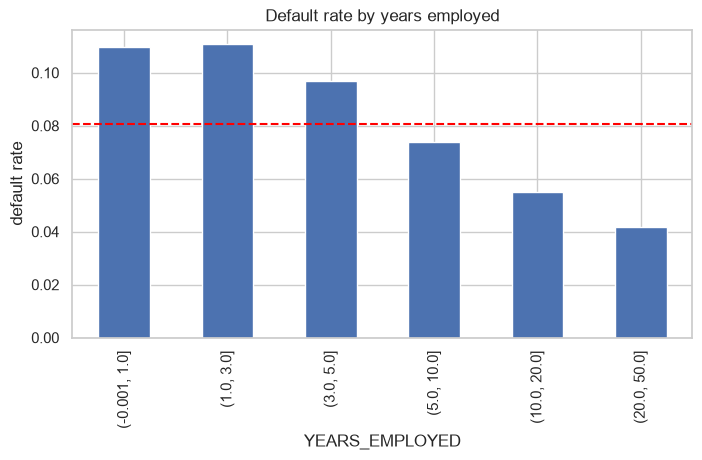

In [18]:
app_train["YEARS_EMPLOYED"] = -app_train["DAYS_EMPLOYED"] / 365
emp_bins = pd.cut(app_train["YEARS_EMPLOYED"], bins=[0, 1, 3, 5, 10, 20, 50], include_lowest=True)

emp_rate = app_train.groupby(emp_bins, observed=True)["TARGET"].mean()
emp_rate.plot(kind="bar", figsize=(8, 4))
plt.axhline(app_train["TARGET"].mean(), color="red", linestyle="--")
plt.title("Default rate by years employed")
plt.ylabel("default rate")
plt.show()

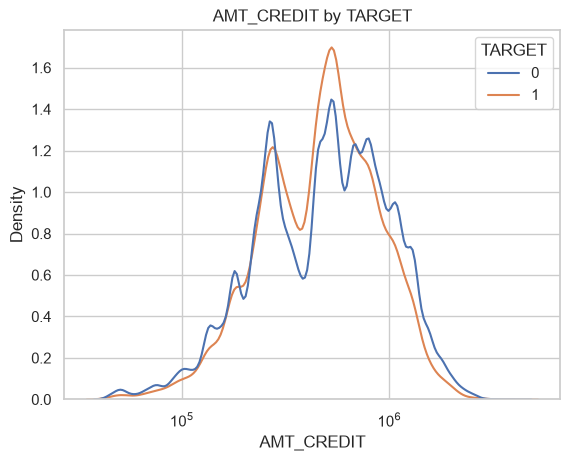

In [19]:
sns.kdeplot(data=app_train, x="AMT_CREDIT", hue="TARGET", common_norm=False, log_scale=True)
plt.title("AMT_CREDIT by TARGET")
plt.show()

- `AMT_CREDIT` (log scale): the distributions of defaulters and non-defaulters overlap almost completely. Both have several peaks at typical loan sizes. Defaulters are slightly more common around 500,000 and non-defaulters slightly more common above 1,000,000. The loan amount alone is a weak separator, but it may help in ratios such as credit to income.

**Answers**
1. The best separators are the three `EXT_SOURCE` columns (especially `EXT_SOURCE_3`) and age. `AMT_CREDIT` separates the groups very little.
2. A lower external score and a younger age go with a higher risk of default.

## 8. Correlations with `TARGET`

**Hints**
- Compute the correlation of every numeric column with `TARGET` and sort it. Look at the strongest positive and negative ones.
- Remember: correlation only measures a linear relationship, and the correlations in this dataset are generally small.
- Plot a heatmap of the `EXT_SOURCE` columns together with `TARGET`, `DAYS_BIRTH` and `AMT_CREDIT`. Strongly correlated features carry overlapping information.

In [20]:
corr = app_train.select_dtypes("number").corr()["TARGET"].sort_values()

print("Most negative:")
print(corr.head(10).round(3))
print("\nMost positive:")
print(corr.tail(10).round(3))

Most negative:
EXT_SOURCE_3         -0.179
EXT_SOURCE_2         -0.160
EXT_SOURCE_1         -0.155
AGE_YEARS            -0.078
YEARS_EMPLOYED       -0.075
DAYS_EMPLOYED_ANOM   -0.046
FLOORSMAX_AVG        -0.044
FLOORSMAX_MEDI       -0.044
FLOORSMAX_MODE       -0.043
AMT_GOODS_PRICE      -0.040
Name: TARGET, dtype: float64

Most positive:
REG_CITY_NOT_LIVE_CITY         0.044
FLAG_EMP_PHONE                 0.046
REG_CITY_NOT_WORK_CITY         0.051
DAYS_ID_PUBLISH                0.051
DAYS_LAST_PHONE_CHANGE         0.055
REGION_RATING_CLIENT           0.059
REGION_RATING_CLIENT_W_CITY    0.061
DAYS_EMPLOYED                  0.075
DAYS_BIRTH                     0.078
TARGET                         1.000
Name: TARGET, dtype: float64


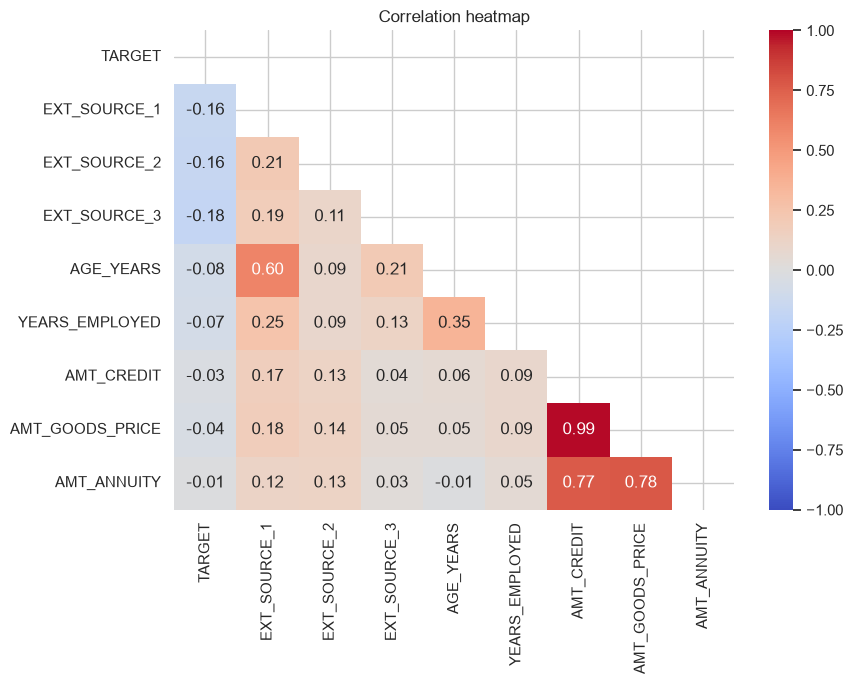

In [21]:
heat_cols = ["TARGET", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
             "AGE_YEARS", "YEARS_EMPLOYED", "AMT_CREDIT", "AMT_GOODS_PRICE", "AMT_ANNUITY"]

corr_matrix = app_train[heat_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

- The strongest correlations with `TARGET` are the three `EXT_SOURCE` columns (-0.16 to -0.18), then age (-0.08) and years employed (-0.07). A higher score, older age and longer employment go with a lower risk.
- The money columns (`AMT_CREDIT`, `AMT_GOODS_PRICE`, `AMT_ANNUITY`) have almost no linear correlation with `TARGET` (-0.01 to -0.04).
- `AMT_CREDIT` and `AMT_GOODS_PRICE` are almost perfectly correlated (0.99), and `AMT_ANNUITY` correlates about 0.77 with both. They carry overlapping information, so one of the first two can be dropped or combined.
- The `EXT_SOURCE` columns correlate only weakly with each other (0.11 to 0.21), so each adds separate information. `EXT_SOURCE_1` correlates 0.60 with age, so part of its signal may come from age.
- All correlations with `TARGET` are small, and correlation only measures straight-line relationships. Models can still use combinations of features.

## 9. Missing values versus `TARGET`

In Milestone 0 you saw that many columns have a lot of missing values. Now check whether **being missing** is related to default.

**Questions to answer**
1. For the columns with the most missing values, is the default rate different for the applicants where the value is missing?
2. Which columns could be dropped, and which should be kept with a "missing" indicator?

**Hints**
- For one column: `app_train.groupby(app_train[col].isna())["TARGET"].mean()`.
- Do this in a loop for the top 20 columns with missing values and sort by the difference.

In [22]:
for col in ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE"]:
    rate = app_train.groupby(app_train[col].isna())["TARGET"].mean().round(4)
    print(col, "| default rate when present / missing:", rate.to_dict())
# rate is a pandas Series with two entries: 
# the index False (value present) and True (value missing), each with a default rate.

EXT_SOURCE_1 | default rate when present / missing: {False: 0.075, True: 0.0852}
EXT_SOURCE_3 | default rate when present / missing: {False: 0.0777, True: 0.0931}
OWN_CAR_AGE | default rate when present / missing: {False: 0.0724, True: 0.085}


In [23]:
top_missing = app_train.isna().mean().sort_values(ascending=False).head(20).index

rows = []
for col in top_missing:
    rate = app_train.groupby(app_train[col].isna())["TARGET"].mean()
    rows.append({"column": col,
                 "rate_present": rate.get(False),
                 "rate_missing": rate.get(True)})

miss_effect = pd.DataFrame(rows).set_index("column")
miss_effect["diff"] = miss_effect["rate_missing"] - miss_effect["rate_present"]
miss_effect.sort_values("diff").round(4)

,rate_present,rate_missing,diff
column,,,
OWN_CAR_AGE,0.0724,0.0850,0.0126
COMMONAREA_MODE,0.0691,0.0857,0.0166
COMMONAREA_AVG,0.0691,0.0857,0.0166
COMMONAREA_MEDI,0.0691,0.0857,0.0166
NONLIVINGAPARTMENTS_AVG,0.0691,0.0858,0.0167
NONLIVINGAPARTMENTS_MODE,0.0691,0.0858,0.0167
NONLIVINGAPARTMENTS_MEDI,0.0691,0.0858,0.0167
FONDKAPREMONT_MODE,0.0689,0.0862,0.0173
LIVINGAPARTMENTS_MODE,0.0689,0.0862,0.0173


In [24]:
housing_cols = [c for c in app_train.columns
                if c.endswith(("_AVG", "_MODE", "_MEDI"))]

app_train["HOUSING_MISSING_COUNT"] = app_train[housing_cols].isna().sum(axis=1)
app_train["HOUSING_INFO_MISSING"] = app_train["COMMONAREA_AVG"].isna().astype(int)

app_train.groupby("HOUSING_INFO_MISSING")["TARGET"].agg(["mean", "count"]).round(4)

,mean,count
HOUSING_INFO_MISSING,,
0,0.0691,92646
1,0.0857,214865


- A single flag `HOUSING_INFO_MISSING` (1 for 70% of applicants) captures the shared missingness of the housing columns: default rate 8.57% when housing information is missing against 6.91% when it is present. Both groups are large, so the difference is reliable.

## 10. First look at the side tables

Load the side tables you need and build a few simple per-applicant features. Check whether they relate to `TARGET`. This also prepares the aggregation for the modelling milestone.

**Ideas to try (pick two or three)**
- `bureau`: number of earlier credits per applicant; number of active credits; total debt.
- `previous_application`: number of earlier applications; share that were refused (`NAME_CONTRACT_STATUS`).
- `installments_payments`: share of payments that were late (`DAYS_ENTRY_PAYMENT` later than `DAYS_INSTALMENT`) or underpaid (`AMT_PAYMENT` smaller than `AMT_INSTALMENT`).
- `credit_card_balance`: whether the applicant has any credit card history at all.

**Hints**
- Aggregate with `groupby("SK_ID_CURR").agg(...)`, then merge onto `app_train` with a **left** join on `SK_ID_CURR`.
- Applicants without records will get missing values. Check how the default rate differs for them.
- The big tables are heavy. Load only the columns you need with `usecols`, and delete tables you no longer need with `del`.

In [25]:
prev = pd.read_csv(DATA_DIR / "previous_application.csv",
                   usecols=["SK_ID_CURR", "SK_ID_PREV", "NAME_CONTRACT_STATUS"])
prev["NAME_CONTRACT_STATUS"].value_counts()

NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64

In [26]:
prev["IS_REFUSED"] = (prev["NAME_CONTRACT_STATUS"] == "Refused").astype(int)
prev["IS_APPROVED"] = (prev["NAME_CONTRACT_STATUS"] == "Approved").astype(int)

prev_feat = prev.groupby("SK_ID_CURR").agg(
    PREV_COUNT=("SK_ID_PREV", "count"),
    PREV_REFUSED_SHARE=("IS_REFUSED", "mean"),
    PREV_APPROVED_SHARE=("IS_APPROVED", "mean"),
).reset_index()

prev_feat.head()

,SK_ID_CURR,PREV_COUNT,PREV_REFUSED_SHARE,PREV_APPROVED_SHARE
0,100001,1,0.0,1.0
1,100002,1,0.0,1.0
2,100003,3,0.0,1.0
3,100004,1,0.0,1.0
4,100005,2,0.0,0.5


In [27]:
app_train = app_train.merge(prev_feat, on="SK_ID_CURR", how="left")

print(app_train.shape)
print("applicants without earlier applications:", app_train["PREV_COUNT"].isna().sum())

(307511, 130)
applicants without earlier applications: 16454


In [28]:
bins = pd.cut(app_train["PREV_REFUSED_SHARE"], bins=[-0.01, 0, 0.25, 0.5, 1.0])
app_train.groupby(bins, observed=True)["TARGET"].agg(["mean", "count"]).round(4)

,mean,count
PREV_REFUSED_SHARE,,
"(-0.01, 0.0]",0.0707,190763
"(0.0, 0.25]",0.0811,47397
"(0.25, 0.5]",0.1133,41739
"(0.5, 1.0]",0.1593,11158


In [29]:
# Applicants with no earlier application:
no_prev = app_train["PREV_COUNT"].isna()
print("no earlier applications:", round(app_train.loc[no_prev, "TARGET"].mean(), 4))
print("has earlier applications:", round(app_train.loc[~no_prev, "TARGET"].mean(), 4))

no earlier applications: 0.0596
has earlier applications: 0.0819


**previous_application**
- Built per-applicant features: number of earlier applications (`PREV_COUNT`) and share refused and approved. 16,454 applicants (5.4%) have no earlier applications.
- The default rate rises with the share of refused earlier applications: 7.1% with no refusals, 8.1% up to 25%, 11.3% for 25 to 50%, and 15.9% above 50%. This is a strong feature.
- First-time customers (no earlier applications) default less often (6.0%) than customers with earlier applications (8.2%), so a "no earlier applications" flag is worth keeping.

In [30]:
bureau_small = pd.read_csv(DATA_DIR / "bureau.csv",
                           usecols=["SK_ID_CURR", "SK_ID_BUREAU", "CREDIT_ACTIVE", "AMT_CREDIT_SUM_DEBT"])

bureau_small["IS_ACTIVE"] = (bureau_small["CREDIT_ACTIVE"] == "Active").astype(int)

bureau_feat = bureau_small.groupby("SK_ID_CURR").agg(
    BUREAU_COUNT=("SK_ID_BUREAU", "count"),
    BUREAU_ACTIVE_COUNT=("IS_ACTIVE", "sum"),
    BUREAU_DEBT_SUM=("AMT_CREDIT_SUM_DEBT", "sum"),
).reset_index()

app_train = app_train.merge(bureau_feat, on="SK_ID_CURR", how="left")
print(app_train.shape)

(307511, 133)


In [31]:
bureau_cols = [c for c in app_train.columns if c.startswith("BUREAU_")]
app_train = app_train.drop(columns=bureau_cols)

app_train = app_train.merge(bureau_feat, on="SK_ID_CURR", how="left")
print(app_train.shape)

(307511, 133)


In [32]:
bins = pd.cut(app_train["BUREAU_ACTIVE_COUNT"], bins=[-1, 0, 1, 3, 100])
app_train.groupby(bins, observed=True)["TARGET"].agg(["mean", "count"]).round(4)

,mean,count
BUREAU_ACTIVE_COUNT,,
"(-1, 0]",0.0566,46341
"(0, 1]",0.0710,74103
"(1, 3]",0.0777,96394
"(3, 100]",0.1072,46653


In [33]:
no_bureau = app_train["BUREAU_COUNT"].isna()
print("no bureau records:  ", round(app_train.loc[no_bureau, "TARGET"].mean(), 4))
print("has bureau records: ", round(app_train.loc[~no_bureau, "TARGET"].mean(), 4))

no bureau records:   0.1012
has bureau records:  0.0773


**bureau**
- Built per-applicant features: number of earlier credits (`BUREAU_COUNT`), number of active credits (`BUREAU_ACTIVE_COUNT`) and total debt (`BUREAU_DEBT_SUM`). 44,020 applicants (about 14%) have no bureau records.
- The default rate rises with the number of active credits at other institutions: 5.7% with none, 7.1% with one, 7.8% with two or three, and 10.7% with more than three.

## 11. Summary and next steps

**Key findings**
- _Which columns show the clearest link with `TARGET`?_
- _Which anomalies and missing-value problems did I find?_
- _Which side-table features look useful?_

**Cleaning decisions for the modelling milestone**
- _For each problem: what will I do about it?_

**Feature ideas**
- _List the features I want to build._

**Next milestone (baseline model, due Day 3, 12:00)**
- Split `app_train` into training and validation with stratification.
- Choose the metric and build a simple baseline.

Before committing: clear all notebook outputs, check that `git status` does not show `data/`, and close the Milestone 1 issue on the Kanban board.

## 11. Summary and next steps

**Key findings**
- Only 8.07% of applicants default, so the data is strongly imbalanced. I will use ROC-AUC as the main metric, plus recall and precision.
- The three `EXT_SOURCE` columns separate defaulters from non-defaulters best (correlations of about -0.16 to -0.18): a lower score means a higher risk. They correlate only weakly with each other (0.11 to 0.21), so each adds information. `EXT_SOURCE_1` correlates 0.60 with age.
- Younger applicants are riskier: the default rate falls from about 11.4% (20 to 30 years) to about 4.9% (60 to 70 years). Men default more often (10.1%) than women (7.0%).
- By income type, Working applicants have the highest default rate (about 9.6%), while pensioners (about 5.3%) and state servants (about 5.7%) have the lowest.
- The loan amount columns (`AMT_CREDIT`, `AMT_GOODS_PRICE`, `AMT_ANNUITY`) have almost no linear correlation with `TARGET` (-0.01 to -0.04). `AMT_CREDIT` and `AMT_GOODS_PRICE` are almost the same column (0.99).
- Side-table features are strong: the default rate rises from 7.1% to 15.9% as the share of refused earlier applications grows, and from 5.7% to 10.7% as the number of active credits at other institutions grows.
- Missing values are not random: applicants with a missing value default more often (about 8.6% against 6.9% for the housing columns).

**Problems found and cleaning decisions**
- `DAYS_EMPLOYED` has the placeholder value 365243 for 55,374 applicants (18%), who default less (5.4% vs 8.7%). Decision: replace it with NaN and keep the flag `DAYS_EMPLOYED_ANOM`.
- `ORGANIZATION_TYPE` = `XNA` marks exactly the same applicants. It is treated as missing.
- `AMT_INCOME_TOTAL` has an extreme outlier (117 million). Decision: cap it or use a log transform.
- `CODE_GENDER` has 4 `XNA` rows. Decision: treat as missing or drop.
- The housing columns (`_AVG`, `_MODE`, `_MEDI`) are 59 to 70% missing and repeat the same information. Decision: keep one version per attribute and add one flag `HOUSING_INFO_MISSING`.
- Fill other missing values (for example with the median) and add "is missing" flags where the gap goes with a higher default rate.
- Gender and age are sensitive attributes in credit decisions. I will test the model with and without them.

**Feature ideas**
- Per-applicant aggregates from all side tables: number and share of refused and approved earlier applications, number of active bureau credits, total debt, late and underpaid instalments, credit card history (only 28% of applicants have it).
- Ratios: credit to income, annuity to income, credit to goods price.
- Combinations of the `EXT_SOURCE` columns (mean, product) and a flag for "no earlier applications".
- Age and years employed in years instead of days.

**Next milestone (baseline model, due Day 3, 12:00)**
- Hold out a final test set from `app_train` and use stratified cross-validation on the rest, because `app_test` has no labels.
- Build the cleaning steps as a function that can be applied to both `app_train` and `app_test`.
- Choose the metric (ROC-AUC, plus recall and precision) and build a simple baseline model, for example logistic regression.